# Web APIs 第六天：正则表达式与阶段案例

## 0. 本课内容与资料

本课对应 JavaScript 第 11 篇。讲义顺序是：正则表达式的介绍、语法、元字符与修饰符 → 小兔鲜注册表单 → 登录页面与首页的阶段案例。

学习目标是利用正则表达式检查输入格式，把单项验证封装为函数，在提交时集中检查；再结合前面学过的事件、DOM、定时器与本地存储，完成页面之间的数据传递和显示。

主资料来自[用户提供的百度网盘分享](https://pan.baidu.com/s/1MxueOHXGQtmE-ypRq1kELA?pwd=9987)，提取码 `9987`，位置为 `1. Pink最新版前端JavaScript / 2.web APIs / 资料 / web APIs第六天`。已逐页读取 `01-PPT/web APIs第六天.pdf` 的全部 52 页公开预览文字与页面图，图片中的代码另外目视核对。必要教学图片裁切后内嵌在本篇中。

练习使用[同课公开代码副本](https://github.com/wukaihang/pink-javascript/tree/main/2.Web%20APIs/day6)。标为“公开副本原代码”的内容保留原变量、缩进、换行、注释及启用状态；标为“摘录”的内容只截取对应部分。讲义转录、整理示例与来源差异在附近说明。

网盘 `02-笔记/README.md` 普通下载要求登录，原 Markdown、原课堂代码及 Xmind 正文尚未取得；`07-作业` 目录显示“暂无文件”。本篇以完整讲义为主，不把公开副本当成网盘原文件，也不补造独立作业。

## 1. 正则表达式

### 1.1 用模式描述要找的内容

**正则表达式（Regular Expression）**是匹配字符串中字符组合的模式。在 JavaScript 中，正则表达式也是对象。

讲义用“在人群里找出戴帽子和眼镜的男人”作比喻：先用条件描述目标，再按条件查找。正则则用一套语法描述字符串应该包含哪些字符、出现多少次，以及处在什么位置。

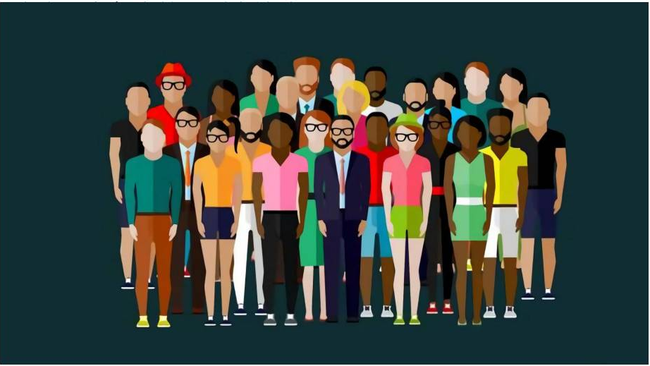

本课的三种用途：

| 用途 | 当前问题 | 对应操作 |
| --- | --- | --- |
| 匹配 | 用户名是否符合允许的字符和长度 | `test()` |
| 提取 | 在文本中找到符合规则的内容 | `exec()` |
| 替换 | 把指定词语替换为其他内容 | 字符串的 `replace()` |

例如表单用户名可以规定为字母、数字、下划线；昵称可以规定为某个汉字范围。要先确定规则，再写正则，不能只看输入中“有没有一个符合的字符”就判定整份输入合格。

### 1.2 定义规则与 test 检测

讲义提到 JavaScript 有两种定义正则的语法，本课先学习字面量：用 `/` 包住匹配模式。

```javascript
const reg = /前端/
```

这里的斜杠是正则字面量的界定符，`前端` 是模式；它不是加了引号的普通字符串。

检测语法是 `reg.test(字符串)`，匹配成功返回 `true`，失败返回 `false`。`/前端/` 只要求字符串中出现“前端”，不要求整个字符串只有这两个字。

`01-正则表达式的使用.html` 公开副本原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    const str = '我们在学习前端，希望学习前端能高新毕业'
    // 1. 定义规则 
    const reg = /前端/
    // 2. 是否包含 规则.test() 返回 true/false
    console.log(reg.test(str))
    // 3. 包含的内容 规则.exec() 返回 数组（包含的内容，索引，原始字符串）/null
    console.log(reg.exec(str))
  </script>
</body>

</html>
```

打开页面看控制台，第一个输出为 `true`，因为文本中包含“前端”。规则定义在 `reg` 上，检测调用也是 `reg.test(str)`，不能反写成 `str.test(reg)`。

### 1.3 exec 检索与返回值

`reg.exec(字符串)` 搜索符合模式的内容。匹配成功返回结果数组，失败返回 `null`。上面的公开代码还执行了 `reg.exec(str)`，能查看匹配内容、位置及输入文本。

| 方法 | 回答什么问题 | 成功 | 失败 |
| --- | --- | --- | --- |
| `test()` | 有没有匹配项 | `true` | `false` |
| `exec()` | 匹配到了什么 | 结果数组 | `null` |

成功时，结果的 `[0]` 是完整匹配文本，`index` 是匹配起点，`input` 是原字符串。前面例子中第一个“前端”的起点为 `5`，索引从 `0` 开始。

下面是按本课语法整理的补充检测，用来观察“不匹配”的返回值：

```javascript
const reg = /前端/
console.log(reg.test('我们在学习后端')) // false
console.log(reg.exec('我们在学习后端')) // null
```

这个例子的正则没有 `g` 修饰符，`exec()` 找到的是第一个匹配项，并不一次返回文中全部“前端”。

### 1.4 普通字符与元字符

普通字母、数字等通常匹配其本身，例如 `/abc/` 查找连续的 `abc`。**元字符**具有特殊含义，用较短的写法表达位置、次数、范围等条件。

讲义将本课元字符分为边界符、量词、字符类。`[a-z]` 就用一个范围表示小写英文字母，不需要逐个写出 26 个候选字符。

讲义参考资料：[MDN 正则表达式](https://developer.mozilla.org/zh-CN/docs/Web/JavaScript/Guide/Regular_expressions)；讲义还列出了[正则测试工具](http://tool.oschina.net/regex)。本篇的示例也可以在浏览器控制台直接测试。

### 1.5 边界符：^ 与 $

边界符描述位置，本身不消耗一个普通字符。

| 写法 | 含义 | 例子 |
| --- | --- | --- |
| `^` | 输入的开头 | `/^二哈/` 要求以“二哈”开头 |
| `$` | 输入的结尾 | `/毕业$/` 要求以“毕业”结尾 |
| `^模式$` | 整个输入符合该模式 | `/^二哈$/` 只接受“二哈” |

按讲义第 20 页代码图片转录：

```javascript
console.log(/哈/.test('哈')) // true
console.log(/二哈/.test('二哈')) // true
console.log(/二哈/.test('很二哈哈')) // true

// ^ 开头
console.log(/^二哈/.test('很二哈哈')) // false
console.log(/^二哈/.test('二哈很傻')) // true
// $ 结尾
console.log(/^二哈$/.test('二哈很傻')) // false
console.log(/^二哈$/.test('二哈二哈')) // false
console.log(/^二哈$/.test('二哈')) // true
```

表单验证通常需要同时写开头与结尾，否则输入的某一小段合格，也可能使 `test()` 返回 `true`。后面的字符集合和数量限制要放在这两个边界之间。

### 1.6 量词：重复多少次

量词限定**前面一个字符或模式**出现的次数。

| 量词 | 次数 | 例子 |
| --- | --- | --- |
| `*` | `0` 次或更多 | `/^哈*$/` 接受空串、一个“哈”、多个“哈” |
| `+` | 至少 `1` 次 | `/^哈+$/` 不接受空串 |
| `?` | `0` 或 `1` 次 | `/^哈?$/` 接受空串或“哈”，不接受“哈哈” |
| `{n}` | 恰好 `n` 次 | `/^哈{2}$/` 只接受“哈哈” |
| `{n,}` | 至少 `n` 次 | `/^哈{2,}$/` 接受两个或更多“哈” |
| `{n,m}` | `n` 到 `m` 次，包含两端 | `/^哈{2,4}$/` 接受两到四个“哈” |

> `{n,m}` 的逗号两边不要写空格。`/^我们*$/` 重复的是“们”，不是整个“我们”；`/前端{2}/` 查找的是“前端端”，不是“前端前端”。公开练习中正好包含这两个例子。

按讲义的“哈”例子整理一组检查：

```javascript
console.log(/^哈*$/.test('')) // true
console.log(/^哈+$/.test('')) // false
console.log(/^哈?$/.test('哈哈')) // false
console.log(/^哈{2}$/.test('哈哈')) // true
console.log(/^哈{2,}$/.test('哈哈哈')) // true
console.log(/^哈{2,4}$/.test('哈哈哈哈哈')) // false
```

`*`、`?` 允许零次，容易使空字符串通过；验证必须填写的输入时，要选合适的量词，而不只是加上 `^`、`$`。

### 1.7 字符类：集合、范围、取反与点

**`[]` 匹配集合中的任意一个字符。**`[abc]` 匹配 `a` 或 `b` 或 `c`，不是一次匹配整个 `abc`。

按本课语法整理的对照：

```javascript
console.log(/[abc]/.test('andy')) // true，包含 a
console.log(/^[abc]$/.test('a')) // true，只有一个字符
console.log(/^[abc]$/.test('ab')) // false
console.log(/^[abc]{2}$/.test('ab')) // true，集合里的字符出现两次
```

**范围：**在集合内用连字符 `-` 表示范围，多个范围可以并列。

| 写法 | 可匹配的单个字符 |
| --- | --- |
| `[a-z]` | 小写英文字母 |
| `[A-Z]` | 大写英文字母 |
| `[a-zA-Z]` | 大小写英文字母 |
| `[0-9]` | 一个数字 |
| `[a-zA-Z0-9_]` | 字母、数字或下划线 |

讲义举出 QQ 号的形式示例 `^[1-9][0-9]{4,}$`：第一位不能是 `0`，后面至少再有 4 位数字。它用于说明范围与量词组合，并不验证账号是否存在。

**取反：**`[^a-z]` 匹配一个不是小写英文字母的字符，`^` 必须在中括号内的开头。`/^[^abc]$/` 的第一个 `^` 是输入开头，第二个 `^` 是集合取反，这两个位置含义不同。

**点：**默认情况下，`.` 匹配除换行等行终止符之外的任意一个字符。要匹配真实的句点可写 `\.`。按本课规则整理的示例：

```javascript
console.log(/^.$/.test('a')) // true
console.log(/^.$/.test('ab')) // false
console.log(/^.$/.test('\n')) // false
console.log(/^\.$/.test('.')) // true
```

> 公开练习 `02-元字符.html` 有一行注释“`[|] 或”，并使用 `[a-z|A-Z|0-9_]`。在中括号中，`|` 是普通候选字符，这种写法会额外允许竖线。合并这些字符范围写 `[a-zA-Z0-9_]` 即可；中括号外的 `|` 才表示分支选择，后面的替换案例会使用它。

短横线本身需要与“范围”区分。后面的原课使用 `[a-zA-Z0-9-_]`；在本例的普通 JavaScript 正则中可以匹配短横线。自己表达字面短横线时，放在集合末尾写 `[a-zA-Z0-9_-]`，或使用 `\-`，可使意图更清楚。本篇保留原码写法。

### 1.8 案例：用户名与中文昵称验证

讲义用户名要求是字母、数字、下划线或短横线，长度为 `6～16` 位，规则为 `/^[a-zA-Z0-9-_]{6,16}$/`。

处理顺序是取得输入框和提示 `span`，在失去焦点时验证；通过时显示正确样式，失败时显示错误样式。讲义使用 `right`、`wrong` 类名，公开副本使用 `right`、`error`。

`03-验证用户名案例.html` 公开副本原代码：

```html
<!DOCTYPE html>
<html lang="en">

<head>
    <meta charset="UTF-8">
    <meta http-equiv="X-UA-Compatible" content="IE=edge">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Document</title>
    <style>
        span {
            display: inline-block;
            width: 500px;
            height: 30px;
            vertical-align: middle;
            line-height: 30px;
            padding-left: 15px;
            font-size: 14px;
        }

        .error {
            color: red;
            background: url(./images/error1.png) no-repeat left center;
        }

        .right {
            color: green;
            background: url(./images/right.png) no-repeat left center;
        }
    </style>
</head>

<body>
    <input type="text">
    <span></span>
    <script>
        const reg = /^[a-zA-Z0-9-_]{6,16}$/
        const input = document.querySelector('input')
        const span = input.nextElementSibling
        input.addEventListener('blur', function () {
            if (reg.test(this.value)) {
                span.className = 'right'
                span.innerHTML = '用户名格式正确'
            } else {
                span.className = 'error'
                span.innerHTML = '用户名格式错误，只能包含字母、数字、下划线和短横线，长度为6-16位'
            }
        })
    </script>
</body>

</html>
```

对应图片是同目录 `images/right.png` 和 `images/error1.png`。输入 `abc_12` 后失去焦点，应显示绿色“用户名格式正确”；输入 `abc`、空串、含中文或空格的内容，应显示红色错误信息。

验证函数中的普通函数 `this` 是当前输入框，读取的是 `this.value`。这里没有先 `.trim()`，所以首尾空格也会使验证失败。

讲义第 32 页的昵称练习要求只输入中文，给出的规则为：

```javascript
const reg = /^[\u4e00-\u9fa5]{2,8}$/
```

沿用上面的输入框、提示和 `blur` 验证结构，替换规则及提示即可。`张三`、`小兔鲜儿` 符合该范围和长度；单个汉字、九个汉字、混入英文字母或数字不符合。

> `\u4e00-\u9fa5` 是原课采用的常用汉字范围，不覆盖全部汉字及中文标点。应表述为“这个范围内的 2～8 个汉字”，不能据此声称支持所有中文字符。

### 1.9 预定义字符类与元字符练习原码

预定义字符类是常用字符范围的简写。本课使用：

| 写法 | 含义 | 本课对应集合 |
| --- | --- | --- |
| `\d` | 数字 | `[0-9]` |
| `\D` | 非数字 | `[^0-9]` |
| `\w` | 英文字母、数字、下划线 | `[A-Za-z0-9_]` |
| `\W` | 上述字符以外的字符 | `[^A-Za-z0-9_]` |
| `\s` | 空白字符，如空格、制表符、换行 | 空白字符类别 |
| `\S` | 非空白字符 | `\s` 的反面 |

`\w` 在本课的普通模式中不表示“所有语言中的文字”，例如中文字符不会因此通过。讲义把 `\s` 类比为常见空白列表；JavaScript 的空白类别还包含其他空白字符，不宜把那个列表当作完整清单。

讲义给出日期格式 `^\d{4}-\d{1,2}-\d{1,2}`，未包含结尾 `$`。如果想检查整个输入的年月日形式，需加结尾边界。公开副本采用两位月、日以及两端边界：`/^\d{4}-\d{2}-\d{2}$/`。

> 此类规则检查的是字符格式。`2023-99-99` 仍会通过公开副本的格式规则；它不判断月份、天数和闰年是否合法。

`02-元字符.html` 公开副本完整原代码，覆盖边界、量词、集合、范围、取反、预定义类和日期格式：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    // 元字符
    // 1. 边界符
    // ^ 表示以...开头
    // $ 表示以...结尾
    // /^...$/精确匹配 只有str为'...'时才为true
    const str = '我们在学习前端端内容非常丰富，我们爱前端，希望学习前端能高新毕业'
    console.log(/^我们/.test(str)) // true
    console.log(/毕业$/.test(str)) // true
    console.log(/^我们毕业$/.test(str)) // false 只有str为'我们毕业'时才为true
    console.log(/^前端/.test(str)) // false
    console.log('-------------------------')
    //2. 量词
    // * 表示0个或多个
    // + 表示1个或多个
    // ? 表示0个或1个
    // {n} 表示重复n个
    // {n,} 表示重复n个或更多个
    // {n,m} 表示重复n个到m个 逗号左右两侧不能有空格
    console.log(/^我们*$/.test(str + '我们')) // false 只有str为'我'+若干个'们'时才为true
    console.log(/^我们*$/.test('我们们')) // true
    console.log(/前端+/.test(str)) // true
    console.log(/^哈+$/.test('哈哈')) // true
    console.log(/^哈?$/.test('哈哈')) // false
    console.log(/前端{2}/.test(str)) // true 包含'前端端'
    console.log(/^哈{4,}$/.test('哈哈哈')) // false
    console.log(/^哈{4,}$/.test('哈哈哈哈')) // true
    console.log(/^哈{4,6}$/.test('哈哈哈哈')) // true
    console.log(/^哈{4,6}$/.test('哈哈哈哈哈哈哈')) // false
    console.log('-------------------------')

    // 3. 字符类
    // [] 匹配字符集的集合
    // 匹配a或b或c
    console.log(/^[abc]$/.test('a')) // true
    console.log(/^[abc]$/.test('b')) // true
    console.log(/^[abc]$/.test('c')) // true
    console.log(/^[abc]$/.test('ab')) // false
    console.log(/^[abc]{2}$/.test('ab')) // true
    console.log('-------------------------')
    console.log(/^[a-z]$/.test('p')) // true
    console.log(/^[a-z]$/.test('P')) // false
    console.log(/^[0-9a-z]$/.test('1')) // true
    console.log(/^[0-9a-z]$/.test('p')) // true
    console.log(/^[A-Z][a-zA-Z0-9-_]{5,17}$/.test('Wukaihang_123456')) // true
    console.log(/^[A-Z][a-zA-Z0-9-_]{5,17}$/.test('wukaihang_123456')) // false
    console.log('-------------------------')
    // [^] 匹配除了字符集的集合
    console.log(/^[^abc]$/.test('a')) // false
    console.log(/^[^abc]$/.test('b')) // false
    console.log(/^[^abc]$/.test('c')) // false
    console.log(/^[^abc]$/.test('d')) // true
    // [|] 或
    console.log(/^[a-z|A-Z|0-9_]$/.test('a')) // true
    console.log(/^[a-zA-Z0-9_]$/.test('1')) // true
    console.log('-------------------------')
    // 4. 预定义类
    // \d 匹配0-9之间的数字
    // \D 匹配非0-9之间的字符
    // \w 匹配0-9a-zA-Z_
    // \W 匹配非0-9a-zA-Z_
    // \s 匹配空格(包括空格、制表符、换行符等)
    // \S 匹配非空格
    console.log(/^\d$/.test('1')) // true
    console.log(/^\D$/.test('1')) // false
    console.log(/^\w$/.test('1')) // true
    console.log(/^\w$/.test('a')) // true
    console.log(/^\w$/.test('_')) // true
    console.log(/^\W$/.test('1')) // false
    console.log(/^\W$/.test('a')) // false
    console.log(/^\W$/.test('_')) // false
    console.log(/^\s$/.test(' ')) // true
    console.log(/^\S$/.test(' ')) // false
    // 日期格式
    // 格式：yyyy-MM-dd
    console.log(/^\d{4}-\d{2}-\d{2}$/.test('2023-03-20')) // true
    console.log(/^\d{4}-\d{2}-\d{2}$/.test('2023-03-201')) // false
  </script>
</body>

</html>
```

对照注释观察控制台布尔值，重点分清“字符串中包含”和“整个字符串符合”。上面已说明的 `|` 注释问题保持原样，阅读时按实际正则行为理解。

### 1.10 修饰符 i、g 与 replace

修饰符写在正则字面量最后一个 `/` 后面，用于调整匹配行为。本课学习两个：

| 修饰符 | 作用 | 本课应用 |
| --- | --- | --- |
| `i` | 忽略英文字母大小写 | 同时匹配 `java` 和 `Java` |
| `g` | 全局匹配 | 替换全部匹配项 |

`字符串.replace(正则, 新内容)` 返回替换后的新字符串，原字符串本身不被修改。没有 `g` 时通常只替换第一个匹配项；有 `g` 时替换所有匹配项。

`04-正则修饰符.html` 公开副本原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    // 修饰符跟在正则表达式的后面
    console.log(/^java$/.test("java")) // true
    console.log(/^java$/.test("Java")) // false
    // 忽略大小写 i
    console.log(/^java$/i.test("Java")) // true
    // 全局匹配 g

    // replace() 方法
    // 格式：str.replace(reg, newStr)
    // 功能：将字符串中符合正则表达式的部分替换为新的字符串
    // 返回值：替换后的字符串
    const str = 'hello java. Java is a good language'
    const re = str.replace(/java/ig, 'js')
    console.log(re) // hello js, js is a good language
  </script>
</body>

</html>
```

前三次检测依次输出 `true`、`false`、`true`。`/java/ig` 同时替换两个大小写不同的单词，结果是 `hello js. js is a good language`。原码末尾注释把句点写成了逗号，实际 `replace()` 没有替换句点，以上实际结果以代码为准。

> 表单格式检测中的规则不需要添加 `g`。带 `g` 的正则会记录 `lastIndex`，重复 `test()` 或 `exec()` 时会从这个位置继续查找；不要把同一个全局规则当成每次都从头检测的无状态验证器。本课表单规则均未使用 `g`。

### 1.11 案例：过滤指定词语

需求是用户输入内容，发布时把命中的词语换成 `**`。要处理每一个出现位置，替换规则带 `g`。`激情|敏感词` 中的 `|` 位于集合外，表示匹配其中任一词语。

`05-过滤敏感词-replace.html` 公开副本原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <textarea name="" id=""></textarea>
  <button>发布</button>
  <div></div>
  <script>
    const tx = document.querySelector('textarea')
    const btn = document.querySelector('button')
    const div = document.querySelector('div')
    btn.addEventListener('click', function () {
      const content = tx.value.trim()
      if (content === '') {
        alert('请输入内容')
        return
      }
      const re = content.replace(/激情|敏感词/ig, '**')
      div.innerHTML = re
      tx.value = ''
    })
  </script>
</body>

</html>
```

处理顺序：读取文本并 `trim()` → 空内容提示并退出 → `replace()` → 写入展示区域 → 清空输入框。输入 `激情和敏感词，激情` 后，结果为 `**和**，**`；只输入空格时弹出“请输入内容”，不会发布。

这是匹配固定词语的课堂例子。它先接收输入，再替换展示内容，并非在键盘输入时禁止那些词语。

> 原例用 `div.innerHTML` 展示输入。词语替换不会让任意输入自动成为安全的 HTML；如果内容应当按普通文本显示，展示语句可使用 `div.textContent = re`。本篇保留原码，练习使用普通文本。

## 2. 综合案例：小兔鲜注册页面

### 2.1 页面与业务模块

本课把前面的格式检测接入已有注册页面。目标文件是公开副本 `综合案例素材/register.html`，配套样式为 `css/common.css`、`css/register.css`，图片资源在 `images`、`uploads` 中。

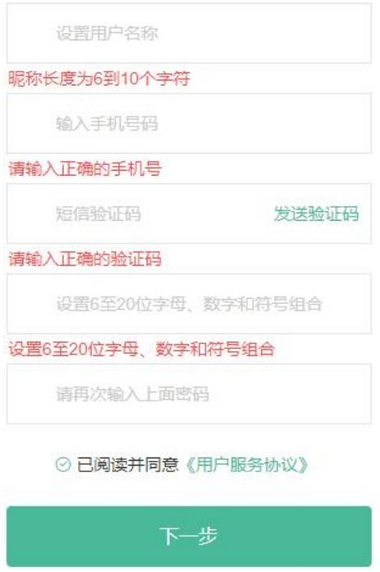

讲义分为四个模块：发送验证码、各表单项验证、勾选已阅读协议、点击下一步时集中验证。只要有输入不合格，就阻止提交。

公开副本中注册卡片的 **HTML 原码摘录**，包含输入的 `name`、紧随其后的提示 `span`、验证码链接、协议图标和提交按钮：

```html
      <!-- 卡片 -->
      <div class="xtx-card">
        <h3>新用户注册</h3>
        <form class="xtx-form">
          <div data-prop="username" class="xtx-form-item">
            <span class="iconfont icon-zhanghao"></span>
            <input name="username" type="text" placeholder="设置用户名称">
            <span class="msg"></span>
          </div>
          <div data-prop="phone" class="xtx-form-item">
            <span class="iconfont icon-shouji"></span>
            <input name="phone" type="text" placeholder="输入手机号码  ">
            <span class="msg"></span>
          </div>
          <div data-prop="code" class="xtx-form-item">
            <span class="iconfont icon-zhibiaozhushibiaozhu"></span>
            <input name="code" type="text" placeholder="短信验证码">
            <span class="msg"></span>
            <a class="code" href="javascript:;">发送验证码</a>
          </div>
          <div data-prop="password" class="xtx-form-item">
            <span class="iconfont icon-suo"></span>
            <input name="password" type="password" placeholder="设置6至20位字母、数字和符号组合">
            <span class="msg"></span>
          </div>
          <div data-prop="confirm" class="xtx-form-item">
            <span class="iconfont icon-suo"></span>
            <input name="confirm" type="password" placeholder="请再次输入上面密码">
            <span class="msg"></span>
          </div>
          <div class="xtx-form-item pl50">
            <i class="iconfont icon-queren"></i>
            已阅读并同意<i>《用户服务协议》</i>
          </div>
          <div class="xtx-form-item">
            <button class="submit">下一步</button>
            <!-- <a class="submit" href="javascript:;">下一步</a> -->
          </div>
        </form>
      </div>
```

`name="username"` 等字段用于定位输入框。`input.nextElementSibling` 对应它后面的 `.msg`，用于显示错误信息。`data-prop` 是原素材中的分组属性；当前脚本主要通过 `name` 选择控件。

### 2.2 发送验证码：5 秒倒计时与点击开关

讲义要求点击“发送验证码”后显示 `05秒后重新获取`，等待完成后恢复为“重新获取”。公开副本初始文本为“发送验证码”，倒计时文本为“05秒后重新发送”。

原脚本先判断 `flag`：

1. 初始 `flag = true`，允许进入点击逻辑。
2. 点击后立刻设为 `false`，避免重复开启多个定时器。
3. `i = 5`，立即更新文本，每秒减 `1`。
4. `i <= 0` 时清除定时器、恢复文本和 `flag = true`。

原课把这种布尔开关称为“节流阀”。它控制的是该处理逻辑能否再次启动，链接本身没有变成原生禁用控件。倒计时期间再次点击会直接 `return`。

这里没有向服务器发送短信，下面的“验证码验证”也只检查六位数字的格式；不能把显示倒计时视为真实发送或校验成功。

### 2.3 change 事件与可复用验证函数

讲义先写“失去焦点触发”，再明确使用 `change`。对文本输入框来说，通常在内容发生变化、失去焦点并提交此次编辑时触发 `change`；仅鼠标移出输入框不等于触发，值没变时单纯失去焦点也不会每次触发。

| 事件 | 本课应如何区分 |
| --- | --- |
| `input` | 输入内容改变时实时触发 |
| `blur` | 失去焦点时触发，不要求内容改变 |
| `change` | 对文本框，改变内容后提交此次编辑，通常在失去焦点时触发 |

`06-change事件.html` 公开副本原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <input type="text">
  <script>
    // change事件 内容发生了变化
    const input = document.querySelector('input')
    input.addEventListener('change', function () {
      console.log(this.value)
    })
  </script>
</body>

</html>
```

输入文本后点击其他位置，控制台输出新的内容；再聚焦并不修改内容，失去焦点时不会因此重复输出。

注册页把验证封装为 `verifyName()`、`verifyPhone()`、`verifyCode()`、`verifyPassword()`、`verifyConfirm()`。变化时调用一次，提交时再主动调用，不依赖用户是否刚触发过 `change`。

每个验证函数都按“取得提示区域 → 检测 → 失败显示提示并返回 `false` → 成功清除提示并返回 `true`”处理。返回布尔值是为了后面组合判断。

### 2.4 用户名、手机号、验证码与密码

| 项目 | 公开副本规则 | 含义 |
| --- | --- | --- |
| 用户名 | `/^[a-zA-Z0-9_]{6,10}$/` | 6～10 位字母、数字或下划线 |
| 手机号 | <code>/^1(3\d&#124;4[5-9]&#124;5[0-35-9]&#124;6[567]&#124;7[0-8]&#124;8\d&#124;9[0-35-9])\d{8}$/</code> | 符合原课列出的号段形式，共 11 位数字 |
| 验证码 | `/^\d{6}$/` | 恰好 6 位数字 |
| 密码 | `/^[a-zA-Z0-9-_]{6,20}$/` | 6～20 位所列字符 |
| 再次输入密码 | `confirm.value !== password.value` | 检查两次输入是否相同 |

**用户名差异：**讲义第 41 页使用 `/^[a-zA-Z0-9-_]{6,10}$/`，允许短横线；公开副本不包含短横线，提示也写“字母、数字或下划线”。因此 `abc-def` 在公开注册页会失败，但在前面 6～16 位用户名案例会成功。两处长度和字符规则都不能混用。

手机号中 `(...)` 把第二、三位的候选号段组合起来，`|` 选择其中一个分支，后面 `\d{8}` 再补八位数字。例如 `3\d` 表示第二位是 `3`、第三位是任意数字；`5[0-35-9]` 的第三位范围排除了 `4`。这是原课给出的号段规则，不能据此保证覆盖今后全部号段或号码已被分配。

验证码只判断格式，不与真实短信内容比较。密码提示“字母、数字和符号组合”，但原正则仅限制字符范围和长度，不强制同时包含字母、数字、符号；`123456` 在原例中可以通过。

再次输入密码没有独立的正则。两项都为空时，单独的 `verifyConfirm()` 可能返回 `true`，但提交还会检查 `verifyPassword()`，空密码无法通过完整检查。先确认一致后又修改密码，确认提示可能还没立即更新，提交时重新验证会发现不一致。

### 2.5 协议勾选与提交拦截

注册页使用图标模拟协议选择：点击 `.icon-queren` 时，通过 `classList.toggle('icon-queren2')` 添加或移除选中类。

`classList.contains('icon-queren2')` 判断图标是否包含选中类，返回布尔值。未勾选时提示“请勾选同意协议”并 `preventDefault()`；任何验证函数返回 `false` 时也阻止默认提交。

原代码把表单项判断写成：

```javascript
if (!verifyName() || !verifyPhone() || !verifyCode() ||
  !verifyPassword() || !verifyConfirm()) {
  e.preventDefault()
}
```

`!` 把“不通过”转换为 `true`，`||` 表示只要有一项不通过就阻止提交。`||` 会短路：前一项已失败时，后面的验证函数可能不会被调用。所以这里保证遇到失败就拦截，并不保证一次点击立刻刷新所有字段的提示。

**提交差异：**讲义明确使用表单的 `submit` 事件，公开副本监听的是 `.submit` 按钮的 `click`。理解原码时按点击按钮的流程观察；按讲义练习时可以把提交检查放在 `.xtx-form` 的 `submit` 事件中，让提交入口统一。

按讲义提交事件思路整理的监听器，可用来**替换**完整原码最后的按钮监听；前提是已有各验证函数及 `queren`，不要同时再注册原来的按钮拦截逻辑：

```javascript
const form = document.querySelector('.xtx-form')
form.addEventListener('submit', function (e) {
  if (!queren.classList.contains('icon-queren2')) {
    alert('请勾选同意协议')
    e.preventDefault()
  }
  if (!verifyName() || !verifyPhone() || !verifyCode() ||
    !verifyPassword() || !verifyConfirm()) {
    e.preventDefault()
  }
})
```

全部通过时不阻止默认提交，但原页面未提供真实注册接口，表单 `action` 为空。本课重点是判断和拦截，不代表已创建用户账号，也没有自动保存注册信息供登录比对。

### 2.6 注册页完整业务脚本与检查

`综合案例素材/register.html` 的 **公开副本原脚本完整摘录**，包含倒计时、五个验证函数、协议切换与提交模块：

```javascript
    // 1. 发送短信验证码模块
    const code = document.querySelector('.code')
    let flag = true // 通过flag控制获取验证码是否可点击 节流阀
    code.addEventListener('click', function () {
      if (!flag) return
      flag = false
      let i = 5
      code.innerHTML = `0${i}秒后重新发送`
      let timer = setInterval(() => {
        i--
        code.innerHTML = `0${i}秒后重新发送`
        if (i <= 0) {
          clearInterval(timer)
          code.innerHTML = '重新获取'
          flag = true
        }
      }, 1000)
    })

    // 2. 验证用户名
    // 2.1 获取用户名输入框
    const username = document.querySelector('[name="username"]')
    // 2.2 验证用户名
    username.addEventListener('change', verifyName)
    // 2.3 实现验证函数
    function verifyName() {
      const span = username.nextElementSibling
      // 2.4 定义规则
      const reg = /^[a-zA-Z0-9_]{6,10}$/
      if (!reg.test(username.value)) {
        span.innerHTML = '请输入6~10位字母、数字或下划线'
        return false
      }
      span.innerHTML = ''
      return true
    }

    // 3. 验证手机号
    // 3.1 获取手机号输入框
    const phone = document.querySelector('[name="phone"]')
    // 3.2 验证手机号
    phone.addEventListener('change', verifyPhone)
    // 3.3 实现验证函数
    function verifyPhone() {
      const span = phone.nextElementSibling
      // 3.4 定义规则
      const reg = /^1(3\d|4[5-9]|5[0-35-9]|6[567]|7[0-8]|8\d|9[0-35-9])\d{8}$/
      if (!reg.test(phone.value)) {
        span.innerHTML = '请输入正确的手机号'
        return false
      }
      span.innerHTML = ''
      return true
    }

    // 4. 验证验证码
    // 4.1 获取验证码输入框
    const codeInput = document.querySelector('[name="code"]')
    // 4.2 验证验证码
    codeInput.addEventListener('change', verifyCode)
    // 4.3 实现验证函数
    function verifyCode() {
      const span = codeInput.nextElementSibling
      // 4.4 定义规则
      const reg = /^\d{6}$/
      if (!reg.test(codeInput.value)) {
        span.innerHTML = '请输入6位数字验证码'
        return false
      }
      span.innerHTML = ''
      return true
    }

    // 5. 验证密码
    // 5.1 获取密码输入框
    const password = document.querySelector('[name="password"]')
    // 5.2 验证密码
    password.addEventListener('change', verifyPassword)
    // 5.3 实现验证函数
    function verifyPassword() {
      const span = password.nextElementSibling
      // 5.4 定义规则
      const reg = /^[a-zA-Z0-9-_]{6,20}$/
      if (!reg.test(password.value)) {
        span.innerHTML = '请输入6~20位字母、数字、短横线或下划线'
        return false
      }
      span.innerHTML = ''
      return true
    }

    // 6. 再次验证密码
    // 5.1 获取密码输入框
    const confirm = document.querySelector('[name="confirm"]')
    // 5.2 验证密码
    confirm.addEventListener('change', verifyConfirm)
    // 5.3 实现验证函数
    function verifyConfirm() {
      const span = confirm.nextElementSibling
      if (confirm.value !== password.value) {
        span.innerHTML = '两次密码输入不一致'
        return false
      }
      span.innerHTML = ''
      return true
    }

    // 7. 同意协议
    const queren = document.querySelector('.icon-queren')
    queren.addEventListener('click', function () {
      // 切换类 原来没有就添加 有就移除
      this.classList.toggle('icon-queren2')
    })

    // 8.提交模块
    const submit = document.querySelector('.submit')
    submit.addEventListener('click', function (e) {
      // 8.1 验证是否勾选同意协议
      // classList.contains() 判断是否包含某个类名
      if (!queren.classList.contains('icon-queren2')) {
        alert('请勾选同意协议')
        e.preventDefault()
      }
      // 8.2 验证其他表单项是否符合要求
      if (!verifyName() || !verifyPhone() || !verifyCode() ||
        !verifyPassword() || !verifyConfirm()) {
        e.preventDefault()
      }
    })


  
```

将脚本放在前面注册 HTML 结构之后，使用配套 `css/common.css`、`css/register.css` 观察样式。公共页头页尾是现有小兔鲜素材；本篇摘录当前要改的表单结构与脚本。

检查顺序：

1. 点击发送验证码，再次点击不应重开倒计时；约五秒后恢复“重新获取”。
2. 输入 `abc` 再离开用户名框，显示错误；改为 `abc_12` 后离开，提示消失。
3. 手机号少一位、验证码不是六位数字、密码不足六位、两次密码不同，分别出现对应错误。
4. 不勾协议点击下一步，提交被阻止。
5. 勾协议但字段不通过时，提交仍被阻止；字段都符合原规则时才允许默认提交。

## 3. 阶段案例：登录、首页与退出

### 3.1 小兔鲜登录页面与 Tab 切换

目标文件为 `综合案例素材/login.html`，样式为 `css/common.css`、`css/login.css`。登录区有“账户登录”和“二维码登录”两个面板。

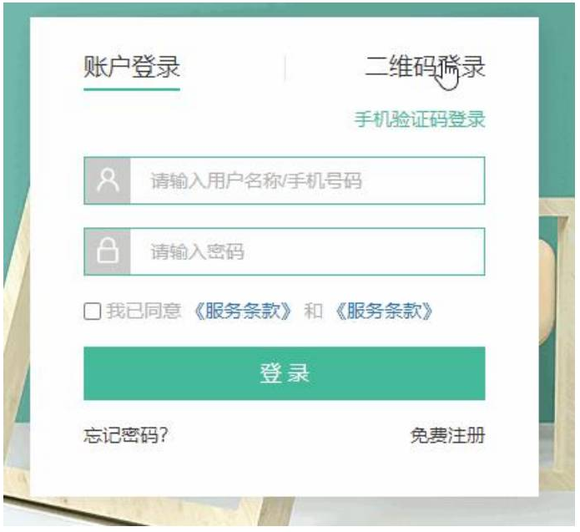

登录区 **公开副本 HTML 原码摘录**：

```html
  <!-- 登录内容 -->
  <div class="xtx-login-main">
    <div class="wrapper">
      <form action="" autocomplete="off">
        <div class="box">
          <div class="tab-nav">
            <a href="javascript:;" class="active" data-id="0">账户登录</a>
            <a href="javascript:;" data-id="1">二维码登录</a>
          </div>
          <div class="tab-pane">
            <div class="link">
              <a href="javascript:;">手机验证码登录</a>
            </div>
            <div class="input">
              <span class="iconfont icon-zhanghao"></span>
              <input required type="text" placeholder="请输入用户名称/手机号码" name="username">
            </div>
            <div class="input">
              <span class="iconfont icon-suo"></span>
              <input required type="password" placeholder="请输入密码" name="password">
            </div>
            <div class="agree">
              <label for="my-checkbox">
                <input type="checkbox" value="1" id="my-checkbox" class="remember" name="agree">
                <span class="iconfont icon-xuanze"></span>
              </label>
              我已同意 <a href="javascript:;">《服务条款》</a href="javascript:;"> 和 <a>《服务条款》</a>
            </div>
            <div class="button clearfix">
              <button type="submit" class="dl">登 录</button>
              <!-- <a class="dl" href="./center.html">登 录</a> -->
              <a class="fl" href="./forget.html">忘记密码？</a>
              <a class="fr" href="./register.html">免费注册</a>
            </div>
          </div>
          <div class="tab-pane" style="display: none;">
            <img class="code" src="./images/code.png" alt="">
          </div>
        </div>
      </form>
    </div>
  </div>
```

两个导航链接分别带 `data-id="0"`、`data-id="1"`，对应 `querySelectorAll('.tab-pane')` 的顺序。原脚本在 `.tab-nav` 上委托点击：

1. 只有 `e.target.tagName === 'A'` 时处理。
2. 移除旧链接的 `active`，给当前链接添加 `active`。
3. 把所有面板设为 `display: none`。
4. 按 `e.target.dataset.id` 显示对应面板。

点击二维码登录时，账户面板隐藏、二维码图片 `images/code.png` 显示；点击账户登录时恢复。该二维码是配套静态素材，没有扫码登录接口。

### 3.2 登录提交：required、协议与本地存储

讲义要求先阻止默认行为，再检查是否同意协议；用户名和密码带 `required`，不能为空。假设登录成功后，把用户名放到本地存储，然后跳转首页。

`required` 是浏览器表单约束：通过正常提交入口且必填项为空时，浏览器会提示并阻止提交。它不能证明用户名已注册或密码正确，也不会把纯空白用户名自动当作空值。

在表单 `submit` 处理中：

1. `e.preventDefault()` 阻止表单默认导航。
2. `agree.checked` 为 `false` 时，提示并 `return`。
3. `localStorage.setItem('xtx-uname', username.value)` 保存用户名。
4. `location.href = './index.html'` 跳转同目录首页。

`综合案例素材/login.html` **公开副本原脚本完整摘录**：

```javascript
    // 1. tab栏切换
    const tab_nav = document.querySelector('.tab-nav')
    const tab_panes = document.querySelectorAll('.tab-pane')
    tab_nav.addEventListener('click', function (e) {
      if (e.target.tagName === 'A') {
        // 移除未选中的a的active类名
        this.querySelector('.active').classList.remove('active')
        // 当前元素添加active类名
        e.target.classList.add('active')
        // 切换tab-pane显示
        tab_panes.forEach((item) => {
          item.style.display = 'none'
        })
        // 显示当前tab-pane
        tab_panes[e.target.dataset.id].style.display = 'block'
      }
    })

    // 2. 提交模块
    const form = document.querySelector('form')
    const agree = document.querySelector('[name=agree]')
    const username = document.querySelector('[name=username]')
    form.addEventListener('submit', function (e) {
      e.preventDefault()
      // 同意协议
      if (!agree.checked) {
        return alert('请勾选同意协议')
      }
      // 记录用户名到本地存储
      localStorage.setItem('xtx-uname', username.value)
      // 跳转首页
      location.href = './index.html'
    })
  
```

注册页协议使用图标类，登录页协议是真实复选框，读取的是 `checked`；两种状态判断不能混写。登录页按钮默认提交表单，监听器绑定在 `form` 上。

> 这是讲义明确采用的“假设登录成功”流程。没有向服务器校验密码，也没有读取注册页保存的账号。`xtx-uname` 是用来练习页面显示的字符串，不是有效登录凭据。

公开 HTML 的协议链接中有一个多余的 `</a href="javascript:;">` 结束标签，摘录保留它；浏览器会容错解析。阅读时区分这个素材标记问题与本课的登录脚本。

### 3.3 首页读取用户名与渲染

目标文件为 `综合案例素材/index.html`。从登录页跳转后，首页需要读取 `xtx-uname`，修改顶部导航前两个 `li`。

顶部导航 **公开副本 HTML 原码摘录**：

```html
  <!-- 项部导航 -->
  <div class="xtx_topnav">
    <div class="wrapper">
      <!-- 顶部导航 -->
      <ul class="xtx_navs">
        <li>
          <a href="./login.html">请先登录</a>
        </li>
        <li>
          <a href="./register.html">免费注册</a>
        </li>
        <li>
          <a href="./center-order.html">我的订单</a>
        </li>
        <li>
          <a href="./center.html">会员中心</a>
        </li>
        <li>
          <a href="javascript:;">帮助中心</a>
        </li>
        <li>
          <a href="javascript:;">在线客服</a>
        </li>
        <li>
          <a href="javascript:;">
            <i class="mobile sprites"></i>
            手机版
          </a>
        </li>
      </ul>
    </div>
  </div>
```

页面先取得第一个 `li`，再通过 `nextElementSibling` 取得第二个。封装 `render()`，因为初次加载和退出后都需要刷新这两处显示。

有用户名时，第一个 `li` 显示用户名和 `icon-user` 图标，第二个显示“退出登录”；没有时恢复“请先登录”“免费注册”。

`综合案例素材/index.html` 页尾 **公开副本原脚本完整摘录**：

```javascript
    // 1. 获取第一个 li
    const li1 = document.querySelector('.xtx_navs li:first-child')
    const li2 = li1.nextElementSibling
    // 2. 最好做个渲染函数 因为退出登录需要重新渲染
    function render() {
      // 2.1 读取本地存储的用户名
      const uname = localStorage.getItem('xtx-uname')
      console.log(uname)
      if (uname) {
        li1.innerHTML = `
          <a href="javascript:;">
            <i class="iconfont icon-user">${uname}
            </i>
          </a>
        `
        li2.innerHTML = '<a href="javascript:;">退出登录</a>'
      }
      else {
        li1.innerHTML = '<a href="./login.html">请先登录</a>'
        li2.innerHTML = '<a href="./register.html">免费注册</a>'
      }
    }
    // 3. 调用渲染函数
    render()

    // 4. 退出登录模块
    li2.addEventListener('click', function () {
      // 4.2 清除本地存储的用户名
      localStorage.removeItem('xtx-uname')
      // 4.3 重新渲染页面
      render()
    })
  
```

`localStorage.getItem('xtx-uname')` 返回字符串，保存时不需要 JSON 对象转换。刷新首页仍能读到用户名，直到后面主动删除该键。

### 3.4 退出：删除数据后再次渲染

公开副本把点击监听注册在第二个 `li` 上。点击时执行 `localStorage.removeItem('xtx-uname')`，再调用 `render()`，两个导航项恢复默认内容。

监听器挂在 `li` 上，而 `render()` 只替换其 `innerHTML`；`li` 本身未被替换，所以这个监听器仍然保留。未登录时同一位置是“免费注册”，它的链接仍可导航到注册页，点击逻辑也会删除可能存在的用户名键并重渲染。

原脚本把用户名直接拼入 `innerHTML`。课堂用普通用户名即可；需要接收任意文本时，应在显示位置使用文本节点或做必要转义，不能把本地存储中的字符串天然视为可信 HTML。

### 3.5 移动端打开与讲义的后续需求

讲义第 50 页要求：移动端打开时跳转到移动页面；本地有数据时显示“你好 xxxx”，否则显示“请跳转到注册页面”。

公开副本 `index.html` 页头保留了上一课的移动端检测，**原脚本完整摘录**：

```javascript
    // 检测 userAgent（浏览器信息）
    !(function () {
      const userAgent = navigator.userAgent
      // 验证是否为Android或iPhone
      const android = userAgent.match(/(Android);?[\s\/]+([\d.]+)?/)
      const iphone = userAgent.match(/(iPhone\sOS)\s([\d_]+)/)

      // 如果是Android或iPhone，则跳转至移动站点
      if (android || iphone) {
        location.href = 'http://m.itcast.cn'
      }

    })()
  
```

它匹配 Android 或 iPhone 的 User-Agent，命中后跳到 `http://m.itcast.cn`。这是平台检测的课堂写法，不能据此覆盖所有移动设备。

**资料边界：**公开副本只提供该移动端跳转，桌面首页显示的是用户名及登录/注册链接；没有提供目标移动页面里“你好 xxxx”或“请跳转到注册页面”的实现。网盘 `06-素材` 内容尚未取得，本篇保留此项讲义需求，不把外部移动站点或自行编写页面当成原课完成代码。

本地存储受同源限制。本站跳到不同协议、主机或端口的移动地址后，不能自动读取本站的 `xtx-uname`；要演示“读取本地用户名显示问候”，页面需要在可读取同一存储的来源运行。

### 3.6 阶段案例验证路径

在同一来源下打开 `login.html`、`index.html`、`register.html`，保持目录与配套资源关系：

1. 登录页切换两个 Tab，确认只有一个面板显示。
2. 必填项为空时提交，浏览器约束拦截；输入完整但未同意协议时，显示“请勾选同意协议”。
3. 输入普通用户名和课堂用密码、勾协议、点击登录，跳转 `index.html`。
4. 首页顶部显示刚才的用户名，第二项为“退出登录”；刷新后仍保留。
5. 点击退出，Local Storage 中 `xtx-uname` 被删除，首页恢复“请先登录”“免费注册”。
6. 再刷新仍是默认状态；点击免费注册能进入 `register.html`。
7. 模拟 Android 或 iPhone 打开首页，检查移动端跳转分支。

原素材中其他商品、会员、订单链接对应更完整的小兔鲜项目，本课公开副本没有所有目标页面。当前验证关注注册表单、登录区与首页顶部导航，不要求这些链接都已实现。

## 4. 今日作业

讲义第 51 页安排：整理今天的笔记，复习综合案例，复写今日案例和阶段案例；下一天上午复习 Web APIs 阶段，下午准备实战，也可以提前开始。

复写时重点检查：

- `test()` 与 `exec()` 的返回值，包含匹配与完整匹配的区别。
- 边界符、量词、字符集合、预定义类以及 `i`、`g`。
- 用户名与昵称验证，指定词语的全局替换。
- 注册页倒计时开关、五个验证函数的布尔返回值、协议状态和提交拦截。
- 登录页 Tab 与 `required`、用户名的本地保存、首页渲染和退出。

网盘 `07-作业` 目录为空；独立题目及移动端补充素材正文未取得，以上安排依据已完整读取的讲义。